# CCM-v2 / SmolLM2-360M-Instruct — train, resume, and real fast evaluation

**Three modes:** `train_new` starts a fresh cellular layer, `resume_train` loads the previous CCM-v2 result ZIP and continues with **real next-token cross-entropy**, and `evaluate_only` evaluates existing weights without training. Default: `train_new`.

Only `model.model.layers[0].self_attn` is replaced. **All other Transformer blocks remain native and frozen.** No teacher agreement, teacher-output MSE, or teacher response text is used as the training objective or checkpoint gate. The baseline is used only to compute *comparative* quality and latency statistics.

**After training:** validation NLL checkpoint selection → WikiText-2 next-token gold test → labeled ARC-Easy multiple-choice → rule-scored native-vs-CCM chats → full-model CUDA prefill latency → downloadable ZIP containing checkpoint, training history, metrics and transcripts.

**Research limitation:** the CCM consensus is mathematically equivalent to attention over a bounded cellular memory tape. This experiment does not prove a new attention-free architecture. No native KV caching, no `.generate()`; chats use causal full-prefix recomputation. GPU speed is not guaranteed. [GitHub source and PR #113](https://github.com/vtavakkoli/TinyCeNN-LM/pull/113).
**Tokenizer compatibility fix:** HF `apply_chat_template` may return a `BatchEncoding` rather than a tensor. The shared evaluator now normalizes it to `[1, tokens]` before `.shape` or `.to(device)`. Existing Colab kernels reload the helper in the chat cells.


In [1]:
# @title 1. Setup, dependencies and GPU
%pip -q install "transformers==5.17.0" "datasets>=3,<5" "huggingface_hub>=0.36,<2" "safetensors" "accelerate" "pandas" "pytest"
import os,sys,subprocess,json,zipfile,io,time,math,hashlib,random,shutil,traceback
from pathlib import Path
import torch
assert torch.cuda.is_available(), 'Use Runtime > Change runtime type > GPU'
REPO=Path('/content/TinyCeNN-LM')
BRANCH='research/competitive-cenn-feasibility'
if not (REPO/'.git').exists():
    subprocess.run(['git','clone','--quiet','--depth','1','--branch',BRANCH,
        'https://github.com/vtavakkoli/TinyCeNN-LM.git',str(REPO)],check=True)
else:
    subprocess.run(['git','-C',str(REPO),'fetch','--quiet','origin',BRANCH],check=True)
    subprocess.run(['git','-C',str(REPO),'checkout','--quiet',BRANCH],check=True)
    subprocess.run(['git','-C',str(REPO),'reset','--hard','origin/'+BRANCH],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(REPO),'--no-deps'],check=True)
if str(REPO) not in sys.path: sys.path.insert(0,str(REPO))
if str(REPO/'src') not in sys.path: sys.path.insert(0,str(REPO/'src'))
from scripts.benchmark_ccm_consensus_smol360 import (ConsensusAttentionAdapter,
    attention_slot,compare_full_model,load_blocks,paired_latency)
# Reload checked-out helper in an existing Colab Python kernel after git pull.
import importlib
import scripts.real_fast_eval as real_fast_eval_module
importlib.reload(real_fast_eval_module)
from scripts.real_fast_eval import arc_easy_eval,real_chat_eval,CHAT_CASES,render_chat_input
from scripts.ccm_gold_training import gold_training_step,check_gold_metrics
from tinycenn_lm.competitive_consensus_v2 import ConsensusConfig,CompetitiveConsensusCeNN
from transformers import AutoModelForCausalLM,AutoTokenizer
import pandas as pd
from IPython.display import display
DEVICE=torch.device('cuda')
DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('GPU',torch.cuda.get_device_name(0),'Torch',torch.__version__)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 75.3 MB/s eta 0:00:00
GPU Tesla T4 Torch 2.11.0+cu130


In [2]:
# @title 2. Training controls — choose train, resume or evaluation only
MODE = 'train_new'  # @param ['train_new','resume_train','evaluate_only']
PROFILE = 'quick' # @param ['smoke','quick','research']
RESULTS_ZIP = '' # @param {type:'string'}
SLOTS = 128 # @param {type:'integer'}
TAG_WIDTH = 64 # @param {type:'integer'}
CELL_WIDTH = 256 # @param {type:'integer'}
SCORE_SCALE = 2.0 # @param {type:'number'}
LEARNING_RATE = 0.0003 # @param {type:'number'}
SEED = 2031 # @param {type:'integer'}
AUTO_DOWNLOAD_RESULTS = True # @param {type:'boolean'}

# smoke: verify the full workflow; quick: initial GPU research; research: longer run.
PROFILES = {'smoke':(64,12,4,4,6,3),
            'quick':(128,64,12,16,80,16),
            'research':(256,192,32,48,500,50)}
SEQ_LEN,TRAIN_BLOCKS,DEV_BLOCKS,TEST_BLOCKS,TRAIN_STEPS,EVAL_EVERY=PROFILES[PROFILE]
assert MODE in ('train_new','resume_train','evaluate_only')
assert SLOTS >= 2 and SLOTS & (SLOTS-1) == 0
assert TAG_WIDTH > 0 and CELL_WIDTH > 0 and LEARNING_RATE > 0
random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)
OUT=Path('/content/CCM_v2_Smol360_Train_RealFast_Results')
OUT.mkdir(parents=True,exist_ok=True)
print('MODE',MODE,'PROFILE',PROFILE,'TRAIN_STEPS',TRAIN_STEPS,
      'TRAIN/DEV/TEST BLOCKS',TRAIN_BLOCKS,DEV_BLOCKS,TEST_BLOCKS,
      'GPU',torch.cuda.get_device_name(0))


MODE train_new PROFILE quick TRAIN_STEPS 80 TRAIN/DEV/TEST BLOCKS 64 12 16 GPU Tesla T4


In [3]:
# @title 3. Optional prior checkpoint ZIP — only resume/evaluate modes request upload
ckpt=None;raw=None;prior_report=None;archive=None
if MODE != 'train_new':
    if RESULTS_ZIP and Path(RESULTS_ZIP).is_file():
        archive=Path(RESULTS_ZIP)
    else:
        from google.colab import files
        print('Upload your previous CCM-v2 results ZIP containing best_ccm_consensus_layer0.pt')
        uploaded=files.upload()
        assert len(uploaded)==1, 'Upload exactly one checkpoint/results ZIP'
        archive=Path('/content')/next(iter(uploaded))
    if not archive.is_file() or not zipfile.is_zipfile(archive):
        raise ValueError('Expected a valid checkpoint ZIP')
    with zipfile.ZipFile(archive) as z:
        matches=[p for p in z.namelist() if p.endswith('best_ccm_consensus_layer0.pt')]
        if len(matches)!=1:raise ValueError('Expected exactly one best_ccm_consensus_layer0.pt')
        member=z.getinfo(matches[0])
        if not (0 < member.file_size < 200_000_000):
            raise ValueError('Checkpoint file is unexpectedly large or empty')
        raw=z.read(member)
        ckpt=torch.load(io.BytesIO(raw),map_location='cpu',weights_only=True)
        matches_report=[p for p in z.namelist() if p.endswith('final_report.json')]
        if len(matches_report)==1:
            prior_report=json.loads(z.read(matches_report[0]).decode('utf-8'))
    if not all(k in ckpt for k in ('config','core','revision','step')):
        raise ValueError('Checkpoint missing config/core/revision/step')
    print('Loaded checkpoint step',ckpt['step'],'revision',ckpt['revision'])
    if MODE=='resume_train' and 'optimizer' not in ckpt:
        print('Legacy checkpoint has no optimizer state. Resume will start a fresh AdamW optimizer.')
else:
    print('Starting a NEW randomly initialized CCM-v2 layer; no old ZIP required.')


Starting a NEW randomly initialized CCM-v2 layer; no old ZIP required.


In [4]:
# @title 4. Load frozen SmolLM2-360M original; set up only layer-0 CCM
MODEL_ID='HuggingFaceTB/SmolLM2-360M-Instruct'
from huggingface_hub import model_info
revision=str(ckpt['revision']) if ckpt is not None else model_info(MODEL_ID).sha
if prior_report is not None and 'revision' in prior_report:
    assert prior_report['revision']==revision,'Prior report/checkpoint revision mismatch'
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=revision)
# Fast fail here if a future tokenizer return type changes again.
chat_probe_ids=render_chat_input(tokenizer,'What is the capital of Austria?')
assert isinstance(chat_probe_ids,torch.Tensor) and chat_probe_ids.ndim==2
print('Chat template verified:',tuple(chat_probe_ids.shape))
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=revision,
    torch_dtype=DTYPE,attn_implementation='sdpa',trust_remote_code=False).to(DEVICE).eval()
assert model.config.model_type=='llama' and hasattr(model.model.layers[0],'self_attn')
model.requires_grad_(False)
native=model.model.layers[0].self_attn
if ckpt is None:
    config=ConsensusConfig(hidden_size=int(model.config.hidden_size),slots=SLOTS,
                           tag_width=TAG_WIDTH,cell_width=CELL_WIDTH,score_scale=SCORE_SCALE)
else:
    config=ConsensusConfig(**ckpt['config'])
assert config.hidden_size==int(model.config.hidden_size),'Architecture/checkpoint mismatch'
core=CompetitiveConsensusCeNN(config).to(DEVICE)
if ckpt is not None:core.load_state_dict(ckpt['core'],strict=True)
adapter=ConsensusAttentionAdapter(core)
assert model.model.layers[0].self_attn is native
print('Original attention parameters',sum(p.numel() for p in native.parameters()))
print('Cellular replacement parameters',sum(p.numel() for p in core.parameters()),'config',config)
print('Pretrained backbone FROZEN; only CCM parameters will be trainable.')


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Original attention parameters 2457600
Cellular replacement parameters 614402 config ConsensusConfig(hidden_size=960, slots=128, tag_width=64, cell_width=256, score_scale=2.0, max_score_scale=10.0, init_gain=0.1)
Pretrained backbone FROZEN; only CCM parameters will be trainable.


In [5]:
# @title 5. REAL gold-next-token training + validation-NLL checkpoint selection
# This stage does not compute teacher logits for the loss and never gates on teacher agreement.
# For a new model, TEST is intentionally not read before best DEV checkpoint is chosen.
BEST=OUT/'best_ccm_consensus_layer0.pt'
HISTORY=OUT/'train_history.json'
TRAIN_STATUS=OUT/'training_status.json'
train_history=[]
selected_step=int(ckpt['step']) if ckpt is not None else 0
resume_optimizer=bool(ckpt is not None and 'optimizer' in ckpt)
if MODE=='evaluate_only':
    assert ckpt is not None
    BEST.write_bytes(raw)
    print('Evaluation-only: weights restored; no training or optimizer created.')
else:
    train_ids=load_blocks(tokenizer,'train',TRAIN_BLOCKS,SEQ_LEN)
    dev_ids=load_blocks(tokenizer,'validation',DEV_BLOCKS,SEQ_LEN)
    train_rng=random.Random(SEED+int(selected_step))
    optimizer=torch.optim.AdamW(core.parameters(),lr=LEARNING_RATE,weight_decay=0.01)
    if resume_optimizer:
        try:
            optimizer.load_state_dict(ckpt['optimizer'])
            for group in optimizer.param_groups:group['lr']=LEARNING_RATE
            print('Restored optimizer momentum/variance from chosen checkpoint.')
        except (ValueError,KeyError,RuntimeError) as e:
            print('Optimizer incompatible, restarting optimizer:',str(e))
            optimizer=torch.optim.AdamW(core.parameters(),lr=LEARNING_RATE,weight_decay=0.01)
    best_nll=float('inf'); start_step=selected_step
    began=time.perf_counter()
    def score_and_checkpoint(step,train_stats=None):
        global best_nll,selected_step
        core.eval()
        gold=compare_full_model(model,native,adapter,dev_ids,1,DEVICE)
        score=check_gold_metrics(gold)
        row={'step':step,'elapsed_seconds':time.perf_counter()-began,
             **(train_stats or {}),**score,
             'native_gold_accuracy':float(gold['teacher_gold_accuracy']),
             'student_gold_accuracy':float(gold['student_gold_accuracy']),
             'teacher_agreement_diagnostic_only':float(gold['teacher_agreement'])}
        train_history.append(row)
        HISTORY.write_text(json.dumps(train_history,indent=2))
        print('DEV',json.dumps(row))
        if score['gold_nll']<best_nll:
            best_nll=score['gold_nll'];selected_step=step
            # Portable trainable adapter only; never save/modify original SmolLM weights.
            snapshot={'core':{k:v.detach().cpu().clone() for k,v in core.state_dict().items()},
                      'optimizer':optimizer.state_dict(),'config':dict(config.__dict__),
                      'revision':revision,'step':int(step),'selection_dev_gold_nll':best_nll,
                      'method':'gold-only CE for layer0; all pretrained weights frozen'}
            torch.save(snapshot,BEST)
        return row
    completed=0
    try:
        score_and_checkpoint(start_step) # Preserve resumed model if continuing harms quality.
        for i in range(1,TRAIN_STEPS+1):
            j=train_rng.randrange(len(train_ids))
            batch=train_ids[j:j+1].to(DEVICE)
            stats=gold_training_step(model,native,adapter,batch,optimizer)
            completed=i
            if i==1 or i%EVAL_EVERY==0 or i==TRAIN_STEPS:
                score_and_checkpoint(start_step+i,stats)
                assert model.model.layers[0].self_attn is native
        (TRAIN_STATUS).write_text(json.dumps({'status':'completed','start_step':start_step,
             'added_steps':completed,'selected_step':selected_step,
             'mode':MODE,'dev_checkpoint_selection':'ground-truth token NLL'},indent=2))
    except BaseException as e:
        (TRAIN_STATUS).write_text(json.dumps({'status':'failed','reason':repr(e),
            'start_step':start_step,'completed_steps':completed,
            'last_selected_step':selected_step},indent=2))
        (OUT/'training_error.txt').write_text(traceback.format_exc())
        raise
    assert BEST.exists(), 'No valid DEV-selected weights saved'
    chosen=torch.load(BEST,map_location='cpu',weights_only=True)
    core.load_state_dict(chosen['core'],strict=True)
    core.eval()
    print('Training completed; best validation-NLL checkpoint step:',chosen['step'])


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DEV {"step": 0, "elapsed_seconds": 4.61659582499999, "gold_nll": 6.021524944956221, "gold_accuracy": 0.15223097112860892, "gold_nll_delta": 2.8046444069369256, "gold_accuracy_drop": 0.28740157480314965, "native_gold_accuracy": 0.43963254593175854, "student_gold_accuracy": 0.15223097112860892, "teacher_agreement_diagnostic_only": 0.23818897637795275}
DEV {"step": 1, "elapsed_seconds": 6.991405455999995, "train_gold_ce": 6.387782573699951, "train_gold_accuracy": 0.16535432636737823, "grad_norm": 1.4875131845474243, "gold_nll": 5.991390278333128, "gold_accuracy": 0.15223097112860892, "gold_nll_delta": 2.7745097403138326, "gold_accuracy_drop": 0.28740157480314965, "native_gold_accuracy": 0.43963254593175854, "student_gold_accuracy": 0.15223097112860892, "teacher_agreement_diagnostic_only": 0.24081364829396326}
DEV {"step": 16, "elapsed_seconds": 12.206004879999966, "train_gold_ce": 6.861721992492676, "train_gold_accuracy": 0.10236220061779022, "grad_norm": 1.2518748044967651, "gold_nll": 5

,step,train_gold_ce,gold_nll,gold_accuracy,gold_nll_delta,gold_accuracy_drop
0,0,NaN,6.0215,0.1522,2.8046,0.2874
1,1,6.3878,5.9914,0.1522,2.7745,0.2874
2,16,6.8617,5.5353,0.1929,2.3184,0.2467
3,32,5.7311,4.9196,0.2671,1.7028,0.1726
4,48,5.0868,4.2925,0.3156,1.0756,0.1240
5,64,4.9037,3.8442,0.3471,0.6273,0.0925
6,80,4.6656,3.6290,0.3635,0.4121,0.0761


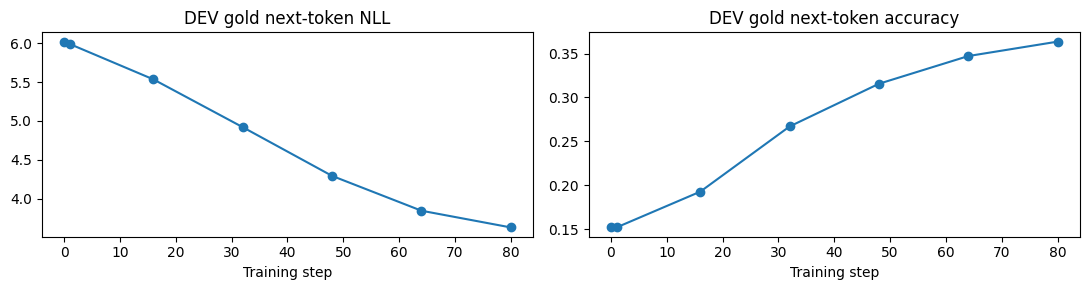

In [6]:
# @title 6. Show training progress (ground-truth NLL and accuracy)
if HISTORY.exists():
    import matplotlib.pyplot as plt
    train_df=pd.DataFrame(json.loads(HISTORY.read_text()))
    display(train_df[['step','train_gold_ce','gold_nll','gold_accuracy',
                      'gold_nll_delta','gold_accuracy_drop']].round(4))
    fig,ax=plt.subplots(1,2,figsize=(11,3))
    ax[0].plot(train_df.step,train_df.gold_nll,marker='o');ax[0].set_title('DEV gold next-token NLL');ax[0].set_xlabel('Training step')
    ax[1].plot(train_df.step,train_df.gold_accuracy,marker='o');ax[1].set_title('DEV gold next-token accuracy');ax[1].set_xlabel('Training step')
    fig.tight_layout();fig.savefig(OUT/'gold_training_curves.png',dpi=150);plt.show()
else:
    print('No training history (evaluation-only mode).')


In [7]:
# @title 7. Ground-truth ARC-Easy multiple-choice evaluation
from datasets import load_dataset
ARC_QUESTIONS = 16 # @param {type:'integer'}
EVAL_SEED = 2031 # @param {type:'integer'}
assert 1 <= ARC_QUESTIONS <= 200
arc_data=load_dataset('allenai/ai2_arc','ARC-Easy',split='validation')
with attention_slot(model,native):
    arc_native=arc_easy_eval(model,tokenizer,dataset=arc_data,limit=ARC_QUESTIONS,seed=EVAL_SEED)
with attention_slot(model,adapter):
    arc_ccm=arc_easy_eval(model,tokenizer,dataset=arc_data,limit=ARC_QUESTIONS,seed=EVAL_SEED)
assert arc_native['evaluated']==arc_ccm['evaluated']>0
assert [r['id'] for r in arc_native['rows']]==[r['id'] for r in arc_ccm['rows']]
print('GOLD-labeled ARC-Easy accuracy native',arc_native['accuracy'],'CCM',arc_ccm['accuracy'])
display(pd.DataFrame([{'id':a['id'],'gold':a['gold'],
 'native_choice':a['pred'],'CCM_choice':b['pred'],
 'native_correct':a['correct'],'CCM_correct':b['correct']}
 for a,b in zip(arc_native['rows'],arc_ccm['rows'])]))


README.md:   0%|          | 0.00/9.00k [00:00<?, ?B/s]

ARC-Easy/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  331kB            

ARC-Easy/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ARC-Easy/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  346kB            

ARC-Easy/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/2251 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2376 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/570 [00:00<?, ? examples/s]

GOLD-labeled ARC-Easy accuracy native 0.375 CCM 0.375


,id,gold,native_choice,CCM_choice,native_correct,CCM_correct
0,Mercury_7008803,A,A,A,True,True
1,Mercury_7248378,A,D,A,False,True
2,Mercury_SC_402278,A,D,A,False,True
3,MCAS_2011_8_17687,B,A,A,False,False
4,Mercury_7186918,B,D,A,False,False
5,NCEOGA_2013_5_15,D,D,A,True,False
6,TIMSS_2007_4_pg35,C,A,A,False,False
7,Mercury_400540,C,A,A,False,False
8,Mercury_7215408,B,D,A,False,False
9,Mercury_SC_LBS10938,D,D,A,True,False


In [8]:
# @title 8. Gold next-token NLL/accuracy and matched CUDA prefill latency
# For 'train_new' this test split was not consulted during checkpoint selection.
# For 'resume_train' or 'evaluate_only' previous runs may already have inspected it.
WIKITEXT_BLOCKS=TEST_BLOCKS # @param {type:'integer'}
CONTEXT_LENGTH=SEQ_LEN # @param {type:'integer'}
assert 1<=WIKITEXT_BLOCKS<=256 and CONTEXT_LENGTH>=16
ids=load_blocks(tokenizer,'test',WIKITEXT_BLOCKS,CONTEXT_LENGTH)
metrics=compare_full_model(model,native,adapter,ids,batch_size=1,device=DEVICE)
latency=paired_latency(model,native,adapter,ids[:1],DEVICE)
assert model.model.layers[0].self_attn is native
print('REAL gold NLL: native',metrics['teacher_nll'],'CCM',metrics['student_nll'])
print('REAL gold token accuracy: native',metrics['teacher_gold_accuracy'],
      'CCM',metrics['student_gold_accuracy'])
print('NLL delta',metrics['delta_nll'], 'full-model prefill GPU speedup',latency['speedup'])
print('Teacher top-1 agreement (not a criterion)',metrics['teacher_agreement'])


REAL gold NLL: native 3.595175765630767 CCM 4.150518177062508
REAL gold token accuracy: native 0.39320866141732286 CCM 0.328248031496063
NLL delta 0.5553424114317406 full-model prefill GPU speedup 0.9938793826618527
Teacher top-1 agreement (not a criterion) 0.5752952755905512


In [9]:
# @title 9. Rule-scored chat evaluation — answers judged by task, not teacher match
# Refresh the module to avoid a stale in-memory function after updating Git.
import importlib
import scripts.real_fast_eval as real_fast_eval_module
importlib.reload(real_fast_eval_module)
real_chat_eval=real_fast_eval_module.real_chat_eval
CHAT_MAX_TOKENS=48 # @param {type:'integer'}
assert 1<=CHAT_MAX_TOKENS<=160
with attention_slot(model,native):
    chat_native=real_chat_eval(model,tokenizer,cases=CHAT_CASES,max_new_tokens=CHAT_MAX_TOKENS)
with attention_slot(model,adapter):
    chat_ccm=real_chat_eval(model,tokenizer,cases=CHAT_CASES,max_new_tokens=CHAT_MAX_TOKENS)
assert model.model.layers[0].self_attn is native
print('Task-rule pass rate native',chat_native['accuracy'],'CCM',chat_ccm['accuracy'])
display(pd.DataFrame([{'task':x['id'],'native_correct':x['pass'],
 'CCM_correct':y['pass'],'native_response':x['response'],'CCM_response':y['response']}
 for x,y in zip(chat_native['rows'],chat_ccm['rows'])]))


Task-rule pass rate native 0.4 CCM 0.0


,task,native_correct,CCM_correct,native_response,CCM_response
0,vienna,True,False,The capital of Austria is Vienna.,200000000000000000000000000000000000
1,math_17_25,False,False,17 + 25 = 42,
2,math_23_19,False,False,23 plus 19 equals 42.,
3,exact_three_words,False,False,Moon,10000000000000000000000000000000000000
4,recall_code,True,False,AURORA-731.,1.\n 2.\n \n 3.\n 2.\n 3.\n 3.\n 3.\n 3.\n 3.\...


In [10]:
# @title 10. Optional custom chat question — preview side by side
CUSTOM_QUESTION = '' # @param {type:'string'}
if CUSTOM_QUESTION.strip():
    import importlib
    import scripts.real_fast_eval as real_fast_eval_module
    importlib.reload(real_fast_eval_module)
    greedy_no_cache=real_fast_eval_module.greedy_no_cache
    with attention_slot(model,native):
        a=greedy_no_cache(model,tokenizer,CUSTOM_QUESTION,max_new_tokens=CHAT_MAX_TOKENS)
    with attention_slot(model,adapter):
        b=greedy_no_cache(model,tokenizer,CUSTOM_QUESTION,max_new_tokens=CHAT_MAX_TOKENS)
    print('ORIGINAL:',a['response'])
    print('CCM:',b['response'])
else:
    print('Set CUSTOM_QUESTION for a personal chat comparison')


Set CUSTOM_QUESTION for a personal chat comparison


In [11]:
# @title 11. Export best trained adapter, history, chat, quality report and downloadable ZIP
from scripts.real_fast_eval import quality_gate
quality=quality_gate(None,metrics,latency,max_delta_nll=0.05,
                     max_gold_accuracy_drop=0.02,min_speedup=1.0)
assert BEST.exists(), 'Missing trained/restored checkpoint'
selected_ckpt=torch.load(BEST,map_location='cpu',weights_only=True)
report={'model':MODEL_ID,'revision':revision,'mode':MODE,'profile':PROFILE,
 'checkpoint_step':int(selected_ckpt['step']),'checkpoint_sha256':hashlib.sha256(BEST.read_bytes()).hexdigest(),
 'training':{'train_steps':TRAIN_STEPS if MODE!='evaluate_only' else 0,
             'gold_ce_only':True,'teacher_loss_used':False,
             'selection':'DEV real-label next-token NLL'},
 'real_wikitext_gold':metrics,'real_arc_easy':{'native':arc_native,'ccm':arc_ccm},
 'real_chat_rule_scored':{'native':chat_native,'ccm':chat_ccm},
 'paired_cuda_prefill':latency,'gold_ground_truth_gate':quality,
 'gold_and_speed_pass':bool(quality['quality_pass'] and quality['speed_pass']),
 'teacher_agreement_used_for_decision':False,
 'test_caution':('WikiText test may have been consulted by the source checkpoint run'
                 if MODE!='train_new' else 'Test loaded only after DEV checkpoint selection'),
 'limits':'Only layer0 mixer replaced; others native; no KV cache; bounded-tape softmax-equivalent cell.'}
(OUT/'final_report.json').write_text(json.dumps(report,indent=2,allow_nan=False))
(OUT/'arc_comparisons.json').write_text(json.dumps({'native':arc_native,'ccm':arc_ccm},indent=2))
(OUT/'chat_behavior.json').write_text(json.dumps({'native':chat_native,'ccm':chat_ccm},indent=2))
(OUT/'run_config.json').write_text(json.dumps({'model':MODEL_ID,'revision':revision,
 'mode':MODE,'profile':PROFILE,'seed':SEED,'sequence_length':SEQ_LEN,
 'train_blocks':TRAIN_BLOCKS,'dev_blocks':DEV_BLOCKS,'test_blocks':WIKITEXT_BLOCKS,
 'core_config':dict(config.__dict__),'learning_rate':LEARNING_RATE,
 'torch_version':torch.__version__,'device':torch.cuda.get_device_name(0)},indent=2))
if prior_report is not None:
    (OUT/'source_report_summary.json').write_text(json.dumps({
      'previous_revision':prior_report.get('revision'),
      'previous_selected_step':prior_report.get('selected_step')},indent=2))
manifest={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.iterdir() if p.is_file()}
(OUT/'file_checksums.json').write_text(json.dumps(manifest,indent=2))
print('Native/CCM gold accuracy:',metrics['teacher_gold_accuracy'],metrics['student_gold_accuracy'])
print('Native/CCM gold NLL:',metrics['teacher_nll'],metrics['student_nll'])
print('ARC gold accuracy:',arc_native['accuracy'],arc_ccm['accuracy'])
print('Five-chat rule accuracy:',chat_native['accuracy'],chat_ccm['accuracy'])
print('Full-model CUDA prefill speedup:',latency['speedup'])
print('PASS gold and speed:',report['gold_and_speed_pass'],'(no teacher-agreement gate)')
final_zip=OUT.parent/(OUT.name+'.zip')
with zipfile.ZipFile(final_zip,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():z.write(p,str(p.relative_to(OUT)))
print('Results and best trainable checkpoint:',final_zip,'size',final_zip.stat().st_size)
if AUTO_DOWNLOAD_RESULTS:
    try:
        from google.colab import files
        files.download(str(final_zip))
    except Exception as e:
        print('Download manually from Colab Files:',repr(e))


Native/CCM gold accuracy: 0.39320866141732286 0.328248031496063
Native/CCM gold NLL: 3.595175765630767 4.150518177062508
ARC gold accuracy: 0.375 0.375
Five-chat rule accuracy: 0.4 0.0
Full-model CUDA prefill speedup: 0.9938793826618527
PASS gold and speed: False (no teacher-agreement gate)
Results and best trainable checkpoint: /content/CCM_v2_Smol360_Train_RealFast_Results.zip size 6893711


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reading the result

- **Training:** default `train_new` trains **only** the CCM-v2 replacement on WikiText-2 train *gold next tokens* (not teacher logits). `resume_train` uses an earlier `best_ccm_consensus_layer0.pt` and restores optimizer state when available; legacy checkpoints start a new optimizer. `evaluate_only` does not train.
- **Checkpoint ranking:** lowest WikiText-2 validation NLL. Native attention is frozen, and all other pretrained parameters remain unchanged. Best checkpoints are written during training, allowing partial recovery if Colab is interrupted.
- **Final quality:** genuine WikiText-2 token accuracy/NLL, gold-labeled ARC-Easy choices, and transparent rule-scored chats. These tests cannot be replaced by teacher agreement. Tiny ARC and chat samples are **screening**, not publication-grade benchmarks.
- **Holdout:** for a **new** run the WikiText test is evaluated only after model selection. A resumed historical checkpoint previously evaluated on WikiText test does **not** regain a sealed holdout. For independent publication evidence, use a genuinely unseen corpus.
- **Timing:** CUDA-event full-model prefill with identical shapes and `use_cache=False`, not cached autoregressive throughput. No speedup is assumed.
- **Novelty:** CCM consensus is equivalent to softmax aggregation over its bounded tape; the language model remains a hybrid with native downstream attention. No model is auto-published.
